In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

def dft_spatial(theta_rad, p_theta, num_modes):
    theta_full = np.append(theta_rad, 2 * np.pi)
    p_full = np.append(p_theta, p_theta[0])
    
    modes = np.arange(1, num_modes + 1)
    amps = np.zeros(num_modes)
    phases = np.zeros(num_modes)

    for i, m, in enumerate(modes):
        real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
        imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

        amps[i] = np.sqrt(real **2 + imag **2)
        phases[i] = np.arctan2(-imag, real)

    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal', scale='linear'):
    if scale == 'linear':
        pass
    elif scale == 'db':
        p_ref = 2e-5
        amps = 20 * np.log10((amps / np.sqrt(2)) / p_ref)

    fig, ax = plt.subplots(figsize=(8,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        if y < 0:
            y = 0
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'temporal':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, Base Frequency = {freqs[0]} Hz")
    elif analysis == 'spatial':
        ax.set_xlabel('Modes', fontweight='bold')
        ax.set_title(f'DFT Extraction of Spatial Periodicity')

    ax.set_ylabel('Amplitdue (Pa)' if scale == 'linear' else 'Sound Pressure Level (dB), Reference = 2e-5 Pa', fontweight='bold')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    # ax.set_xticks(i for i in range(len(freqs)))
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def box_plotter(target_directory, target_observers=None, use_doppler=True):
    # 1. Compile the entire directory using the upgraded batch method
    master = FWHDataset.compile_fwh_batch(target_directory, use_doppler=use_doppler)
    df = pd.DataFrame(master)
    
    # 2. Filter by requested observers
    if target_observers:
        # Standardize inputs to zero-padded strings (e.g., 1 -> '01')
        target_observers = [str(obs).zfill(2) for obs in target_observers]
        df = df[df['observer'].isin(target_observers)]
        
    # Sort dataframe so the x-axis plots sequentially
    df = df.sort_values(by='observer')

    # 3. Generate Boxplot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(data=df, x='observer', y='error', palette='coolwarm', 
                boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
                showfliers=False, ax=ax)

    # 4. Calculate and Stamp Medians
    medians = df.groupby('observer')['error'].median()
    obs_names = sorted(df['observer'].unique())

    for i, obs in enumerate(obs_names):
        median_val = medians[obs]
        text_label = f"{median_val:.2e}" 
        ax.text(i, median_val * 1.05, text_label, 
                horizontalalignment='center', size='small', color='black', weight='bold')

    ax.set_yscale('log')
    ax.set_ylabel('L2 Error (%)')
    
    # Optional: Auto-scale y-limit if the hardcoded bounds clip your multipole data
    # ax.set_ylim(df['error'].min() * 0.5, df['error'].max() * 2.0)
    ax.set_ylim(5e-4, 5e-2) 
    
    ax.set_xlabel('Observer ID')
    ax.set_title(f'Observer Error Variance | Directory: {Path(target_directory).name}')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, which='both')

    plt.tight_layout()
    plt.show()
    
    return df

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


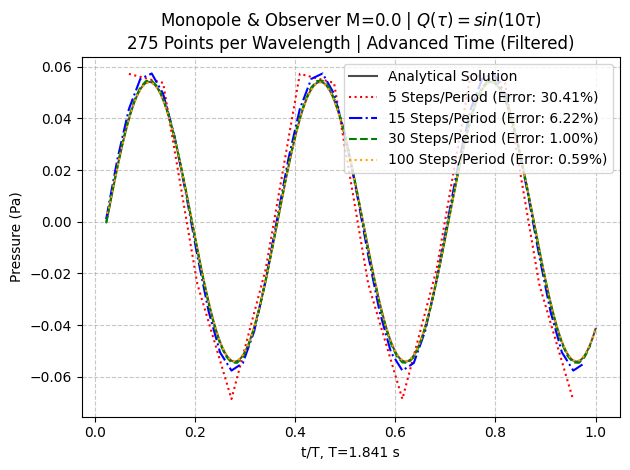

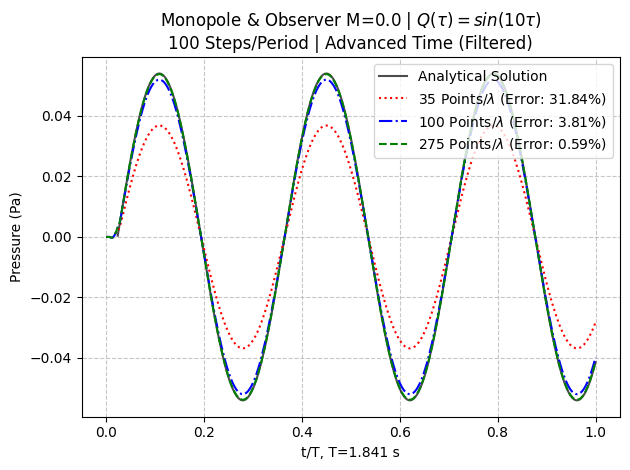

In [85]:
date = '260817'
filepath = Path(f'data_{date}/monopole_validation_stationary_AT')

r = 10 * np.sqrt(2)
c = 340.0
t_start = r / c

x_test_vals = [35, 100, 275]
p_test_vals = [5, 15, 30, 100]

ana_path = filepath / f'ana_spatial_01.dat'
ana_dataset = FWHDataset(filepath=ana_path)

ana_dataset.data = ana_dataset.data[ana_dataset.data['Time'] >= t_start]

target_datasets = []
dataset_labels = []

for p in p_test_vals:
    num_path = filepath / f'X{x_test_vals[-1]}_P{p}_01.dat'
    if num_path.exists():
        ds = FWHDataset(filepath=num_path)
        ds.data = ds.data[ds.data['Time'] >= t_start]

        # target_datasets.append(FWHDataset(filepath=num_path))
        target_datasets.append(ds)
        dataset_labels.append(f'{p} Steps/Period')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf"Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$" + "\n" + f"{x_test_vals[-1]} Points per Wavelength | Advanced Time (Filtered)",
    error_method='l2',
    x_axis='normalised',
    time_method='AT'
)

target_datasets = []
dataset_labels = []

for x in x_test_vals:
    num_path = filepath / f'X{x}_P{p_test_vals[-1]}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(rf'{x} Points/$\lambda$')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf'Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$' + '\n' + f'{p_test_vals[-1]} Steps/Period | Advanced Time (Filtered)',
    error_method='l2',
    x_axis='normalised',
    time_method='AT'
)

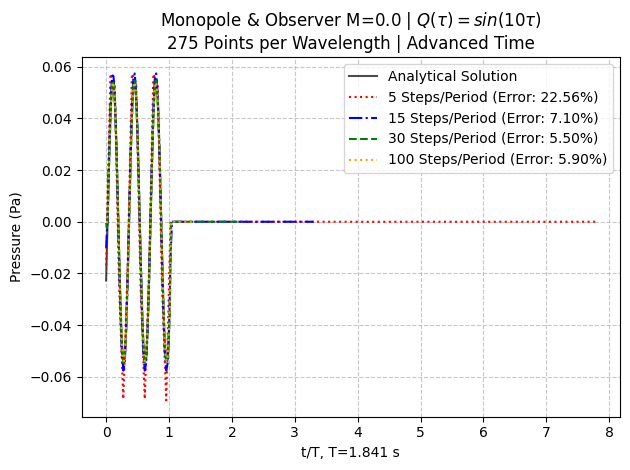

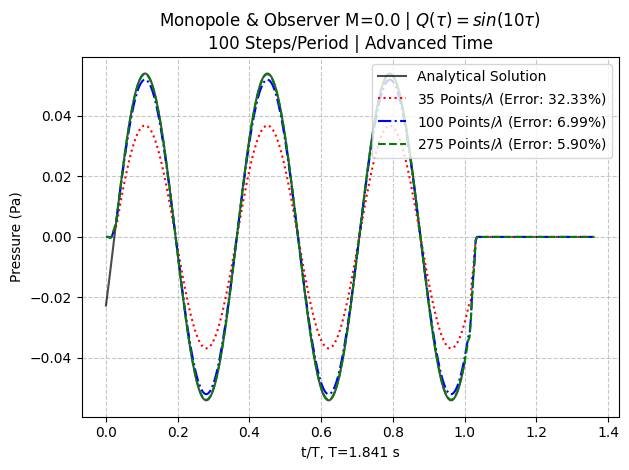

In [89]:
date = '260817'
filepath = Path(f'data_{date}/monopole_validation_stationary_AT')

x_test_vals = [35, 100, 275]
p_test_vals = [5, 15, 30, 100]

ana_path = filepath / f'ana_spatial_01.dat'
ana_dataset = FWHDataset(filepath=ana_path)

target_datasets = []
dataset_labels = []

for p in p_test_vals:
    num_path = filepath / f'X{x_test_vals[-1]}_P{p}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(f'{p} Steps/Period')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf"Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$" + "\n" + f"{x_test_vals[-1]} Points per Wavelength | Advanced Time",
    error_method='l2',
    x_axis='normalised',
    time_method='RT'
)

target_datasets = []
dataset_labels = []

for x in x_test_vals:
    num_path = filepath / f'X{x}_P{p_test_vals[-1]}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(rf'{x} Points/$\lambda$')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf'Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$' + '\n' + f'{p_test_vals[-1]} Steps/Period | Advanced Time',
    error_method='l2',
    x_axis='normalised',
    time_method='RT'
)

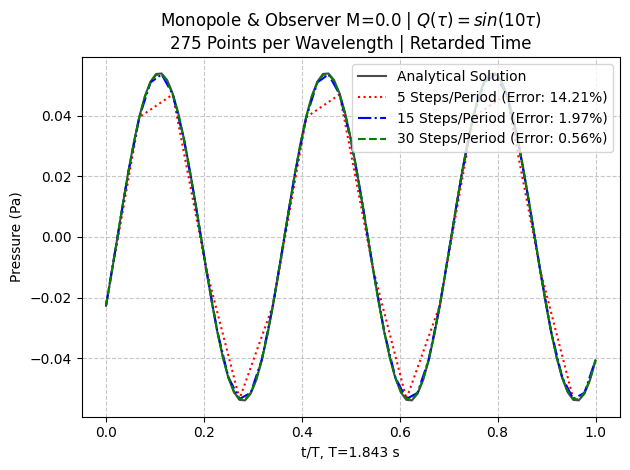

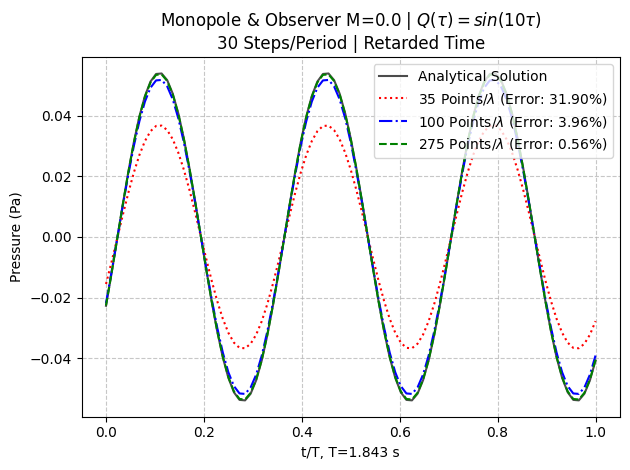

In [79]:
date = '260807'
filepath = Path(f'data_{date}/monopole_validation_stationary')


x_test_vals = [35, 100, 275]
p_test_vals = [5, 15, 30]

ana_path = filepath / f'ana_spatial_01.dat'
ana_dataset = FWHDataset(filepath=ana_path)

target_datasets = []
dataset_labels = []

for p in p_test_vals:
    num_path = filepath / f'X{x_test_vals[-1]}_P{p}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(f'{p} Steps/Period')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf"Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$" + "\n" + f"{x_test_vals[-1]} Points per Wavelength | Retarded Time",
    error_method='l2',
    x_axis='normalised'
)

target_datasets = []
dataset_labels = []

for x in x_test_vals:
    num_path = filepath / f'X{x}_P{p_test_vals[-1]}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(rf'{x} Points/$\lambda$')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf'Monopole & Observer M=0.0 | $Q(\tau)=sin(10\tau)$' + '\n' + f'{p_test_vals[-1]} Steps/Period | Retarded Time',
    error_method='l2',
    x_axis='normalised'
)

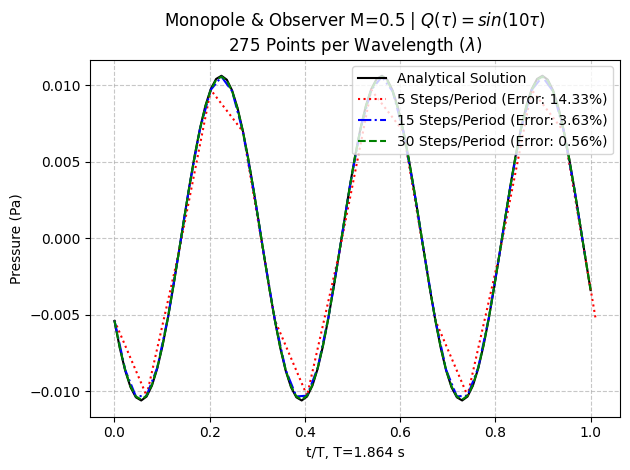

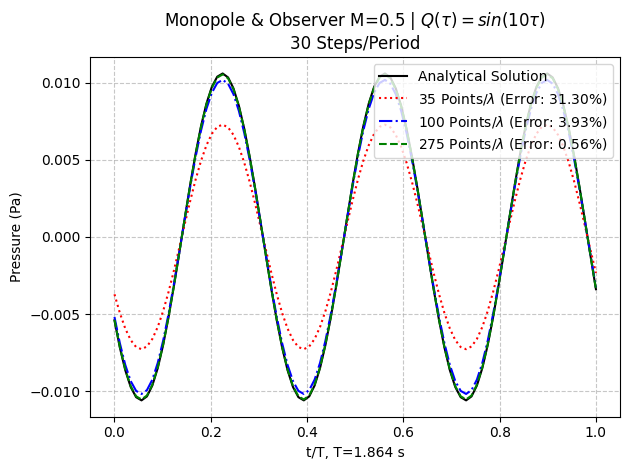

In [68]:
date = '260807'
filepath = Path(f'data_{date}/monopole_validation_cotranslating')

x_test_vals = [35, 100, 275]
p_test_vals = [5, 15, 30]

ana_path = filepath / f'ana_spatial_01.dat'
ana_dataset = FWHDataset(filepath=ana_path)

target_datasets = []
dataset_labels = []

for p in p_test_vals:
    num_path = filepath / f'X{x_test_vals[-1]}_P{p}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(f'{p} Steps/Period')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf"Monopole & Observer M=0.5 | $Q(\tau)=sin(10\tau)$" + "\n" + rf"{x_test_vals[-1]} Points per Wavelength ($\lambda$)",
    error_method='l2',
    x_axis='normalised'
)

target_datasets = []
dataset_labels = []

for x in x_test_vals:
    num_path = filepath / f'X{x}_P{p_test_vals[-1]}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(rf'{x} Points/$\lambda$')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf'Monopole & Observer M=0.5 | $Q(\tau)=sin (10\tau)$' + "\n" f"{p_test_vals[-1]} Steps/Period",
    error_method='l2',
    x_axis='normalised'
)

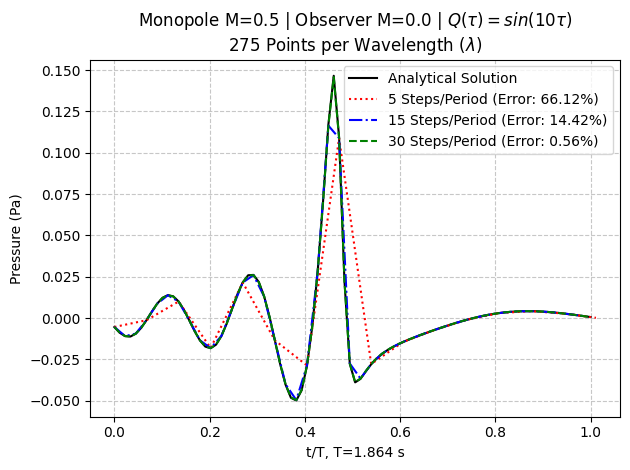

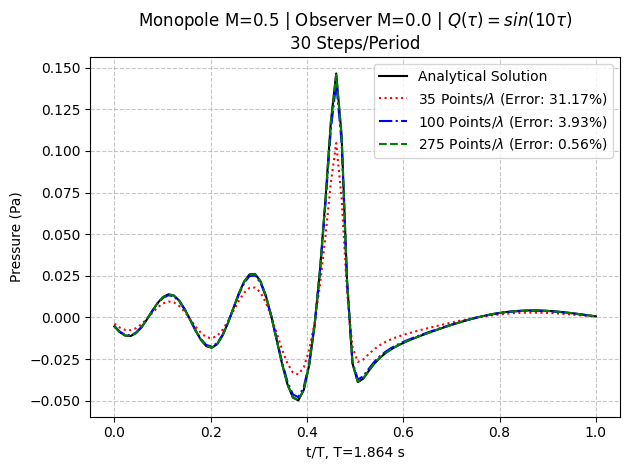

In [67]:
date = '260807'
filepath = Path(f'data_{date}/monopole_validation_translating')

x_test_vals = [35, 100, 275]
p_test_vals = [5, 15, 30]

ana_path = filepath / f'ana_spatial_01.dat'
ana_dataset = FWHDataset(filepath=ana_path)

target_datasets = []
dataset_labels = []

for p in p_test_vals:
    num_path = filepath / f'X{x_test_vals[-1]}_P{p}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(f'{p} Steps/Period')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf"Monopole M=0.5 | Observer M=0.0 | $Q(\tau)=sin(10\tau)$" + "\n" + rf"{x_test_vals[-1]} Points per Wavelength ($\lambda$)",
    error_method='l2',
    x_axis='normalised'
)

target_datasets = []
dataset_labels = []

for x in x_test_vals:
    num_path = filepath / f'X{x}_P{p_test_vals[-1]}_01.dat'
    if num_path.exists():
        target_datasets.append(FWHDataset(filepath=num_path))
        dataset_labels.append(rf'{x} Points/$\lambda$')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *target_datasets, 
    ref_col='P_obs',
    labels=dataset_labels,
    title=rf'Monopole M=0.5 | Observer M=0.0 | $Q(\tau)=sin(10\tau)$' + "\n" f"{p_test_vals[-1]} Steps/Period",
    error_method='l2',
    x_axis='normalised'
)

In [ ]:
# def l2_error(num_data, ref_data, col='Pressure'):
#     ref_df = ref_data.data if hasattr(ref_data, 'data') else ref_data

#     if len(num_data) != len(ref_df):
#         t_fine = ref_df['Time'].values
#         t_coarse = num_data['Time'].values
#         p_coarse = num_data[col].values
#         p_interp = np.interp(t_fine, t_coarse, p_coarse)
#         abs_error = np.linalg.norm(ref_df[col].to_numpy() - p_interp)
#     else:
#         abs_error = np.linalg.norm(ref_df[col].to_numpy() - num_data[col].to_numpy())

#     return abs_error / (np.linalg.norm(ref_df[col]) + 1e-15)

# def time_clip(num_data, ref_data):
#     t_max = ref_data['Time'].max()
#     return num_data[num_data['Time'] <= t_max]


# ref_data = pd.read_csv('data_260817/monopole_validation_stationary_AT/ana_spatial_01.dat', sep='\s+').rename(mapper={"#":"Time", "Point":"Pressure"}, axis=1).drop(columns=["1", ":"])
# x275_P30 = pd.read_csv('data_260817/monopole_validation_stationary_AT/X275_P30_01.dat', sep='\s+').rename(mapper={"#":"Time", "Point":"Pressure"}, axis=1).drop(columns=["1", ":"])

# fig, ax = plt.subplots()
# ax.plot(ref_data['Time'], ref_data['Pressure'], ls='-', c='black', alpha=0.6)
# ax.plot(x275_P30['Time'], x275_P30['Pressure'], ls=':', c='red', alpha=1)

# l2_error(time_clip(x275_P30, ref_data), ref_data)

# l2_error(x275_P30, ref_data)